the detector

In [1]:
pip install ipywidgets

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
Note: you may need to restart the kernel to use updated packages.


In [10]:
import torch
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from transformers import Owlv2Processor, Owlv2ForObjectDetection
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# --- 1. SETUP MODEL ---
device = "cuda" if torch.cuda.is_available() else "cpu"
model_id = "google/owlv2-base-patch16-ensemble"
processor = Owlv2Processor.from_pretrained(model_id)
model = Owlv2ForObjectDetection.from_pretrained(model_id).to(device)
model.eval()

# --- 2. LOAD YOUR REFERENCE CROPS (MULTI-ANGLE) ---
# Pick 2-3 clean crops of Lenny from your "base Lenny" photos
REFERENCE_CROPS = [
    Image.open("images/lenny1.jpg").convert("RGB"),
    Image.open("images/lenny2.jpg").convert("RGB"),
    Image.open("images/lenny3.jpg").convert("RGB"),
    Image.open("images/lenny4.jpg").convert("RGB"),
    Image.open("images/lenny5.jpg").convert("RGB"),
    Image.open("images/lenny6.jpg").convert("RGB"),
    Image.open("images/lenny7.jpg").convert("RGB"),
    Image.open("images/lenny8.jpg").convert("RGB"),
    Image.open("images/lenny9.jpg").convert("RGB"),
    Image.open("images/lenny10.jpg").convert("RGB"),
    Image.open("images/lenny11.jpg").convert("RGB"),
    Image.open("images/lenny12.jpg").convert("RGB"),
    Image.open("images/lenny13.jpg").convert("RGB"),
    Image.open("images/lenny14.jpg").convert("RGB"),
    Image.open("images/lenny15.jpg").convert("RGB"),
    Image.open("images/lenny16.jpg").convert("RGB"),
    Image.open("images/lenny17.jpg").convert("RGB"),
    Image.open("images/lenny18.jpg").convert("RGB"),
    Image.open("images/lenny19.jpg").convert("RGB"),
    Image.open("images/lenny20.jpg").convert("RGB"),
    Image.open("images/lenny21.jpg").convert("RGB"),
    Image.open("images/lenny22.jpg").convert("RGB"),
    Image.open("images/lenny23.jpg").convert("RGB"),
    Image.open("images/lenny24.jpg").convert("RGB"),
    Image.open("images/lenny25.jpg").convert("RGB"),
    Image.open("images/lenny26.jpg").convert("RGB"),
    Image.open("images/lenny27.jpg").convert("RGB"),
    Image.open("images/lenny28.jpg").convert("RGB"),
    Image.open("images/lenny29.jpg").convert("RGB"),
    Image.open("images/lenny30.jpg").convert("RGB"),
    Image.open("images/lenny31.jpg").convert("RGB"),
    Image.open("images/lenny32.jpg").convert("RGB")
]

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

open training images

Total Sample Images  : {len(image_files)}
20261010_192839.jpg -> Size: (4000, 3000) (W x H)
20261010_192844.jpg -> Size: (4000, 3000) (W x H)
20261010_192848.jpg -> Size: (4000, 3000) (W x H)
20261010_192852.jpg -> Size: (4000, 3000) (W x H)
20261010_192856.jpg -> Size: (4000, 3000) (W x H)


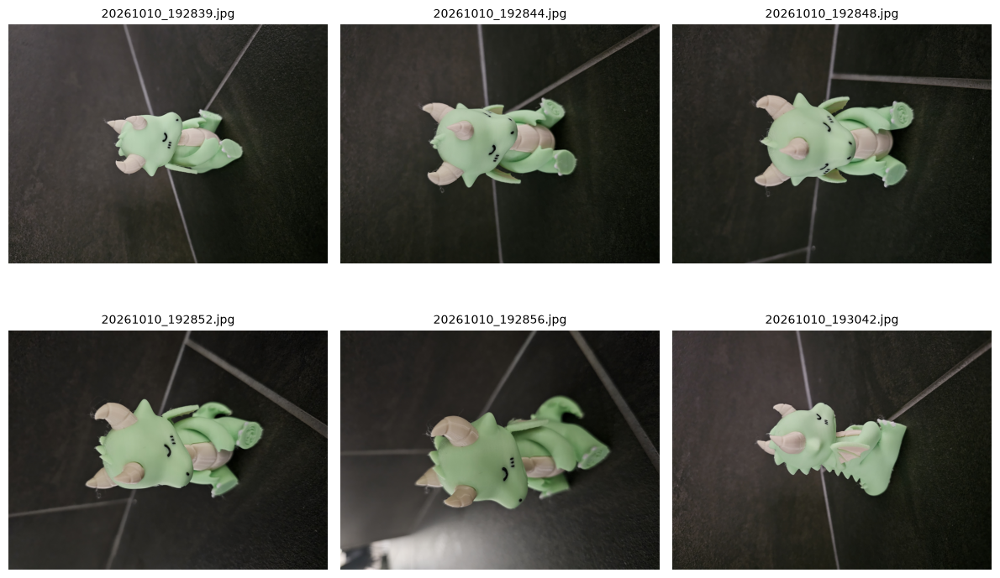

In [3]:
image_dir = Path("images")
image_files = sorted(list(image_dir.glob("*.jpg")) + list(image_dir.glob("*.png")) + list(image_dir.glob("*.jpeg")))

print("Total Sample Images  : {len(image_files)}")

# 2. Check dimensions of first few images (EDA resolution check)
for p in image_files[:5]:
    with Image.open(p) as img:
        print(f"{p.name} -> Size: {img.size} (W x H)")

# 3. Visual EDA: Plot a 2x3 grid of sample photos
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    if i < len(image_files):
        img = Image.open(image_files[i])
        ax.imshow(img)
        ax.set_title(image_files[i].name, fontsize=10)
        ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
def get_lenny_coords(
    image_bytes: bytes,
    size_coords: tuple,                     # (xmin, ymin, xmax, ymax)
    reference_crops: list = REFERENCE_CROPS,
    threshold: float = 0.55                 # Image-guided threshold (0.50 - 0.65)
):
    """
    Scans the room photo against multiple reference angles of Lenny.
    Filters candidate boxes by target dimensions.
    Returns: (center_x, center_y) or (None, None).
    """
    # 1. Target scale from user's box
    u_xmin, u_ymin, u_xmax, u_ymax = size_coords
    target_area = max(abs(u_xmax - u_xmin) * abs(u_ymax - u_ymin), 1)

    # 2. Decode the search image
    search_image = Image.open(io.BytesIO(image_bytes)).convert("RGB")
    width, height = search_image.size
    target_sizes = torch.tensor([[height, width]]).to(device)

    best_candidate_box = None
    best_overall_score = -float("inf")

    # 3. Test each reference angle (Front, Side, Back)
    for ref_crop in reference_crops:
        inputs = processor(
            images=search_image,
            query_images=ref_crop,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            outputs = model.image_guided_detection(**inputs)

        results = processor.post_process_image_guided_detection(
            outputs=outputs,
            threshold=threshold,
            target_sizes=target_sizes
        )[0]

        boxes = results["boxes"]
        scores = results["scores"]

        if len(boxes) == 0:
            continue

        # 4. Score candidates against expected size
        for box, score in zip(boxes, scores):
            b = box.tolist()  # [xmin, ymin, xmax, ymax]
            box_area = max(abs(b[2] - b[0]) * abs(b[3] - b[1]), 1)

            scale_ratio = box_area / target_area
            if scale_ratio > 1.0:
                scale_ratio = 1.0 / scale_ratio

            # Combined confidence and size similarity
            rank_score = float(score) * (scale_ratio ** 0.5)

            if rank_score > best_overall_score:
                best_overall_score = rank_score
                best_candidate_box = b

    # If no angle found Lenny above threshold
    if best_candidate_box is None:
        return None, None

    # 5. Return strictly the center coordinates
    center_x = round((best_candidate_box[0] + best_candidate_box[2]) / 2)
    center_y = round((best_candidate_box[1] + best_candidate_box[3]) / 2)

    return center_x, center_y

test function with test data

🚀 Starting Full Test on 73 photos across 32 angles...

[1/73] Scanning: 20261010_193342.jpg       ->  FOUND (1.00)


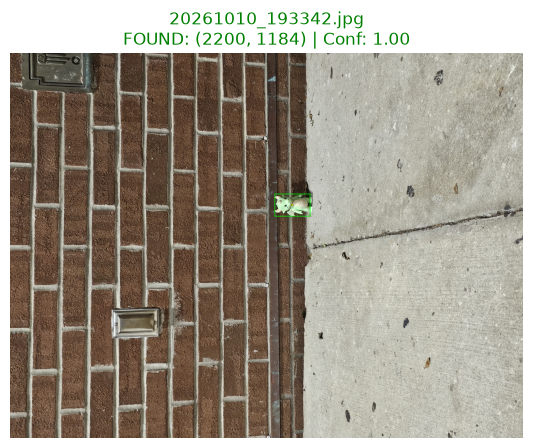

[2/73] Scanning: 20261010_193407.jpg       ->  FOUND (1.00)


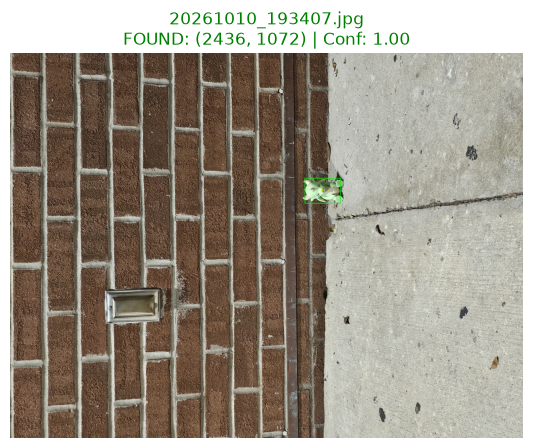

[3/73] Scanning: 20261010_193430.jpg       ->  FOUND (1.00)


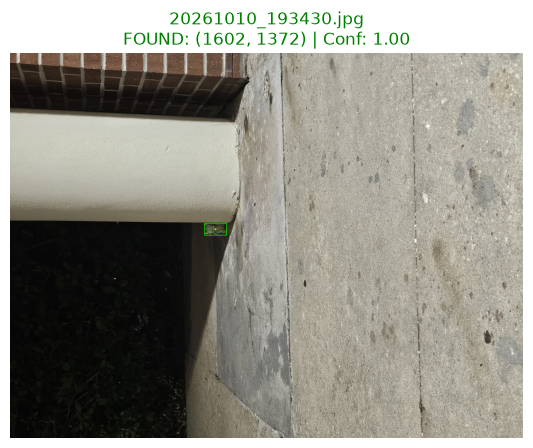

[4/73] Scanning: 20261010_193458.jpg       ->  FOUND (1.00)


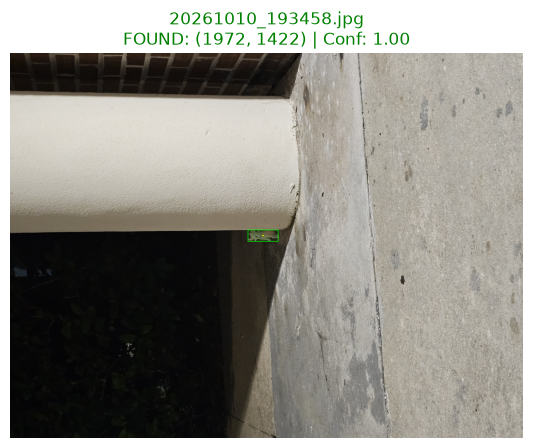

[5/73] Scanning: 20261010_193528.jpg       ->  FOUND (1.00)


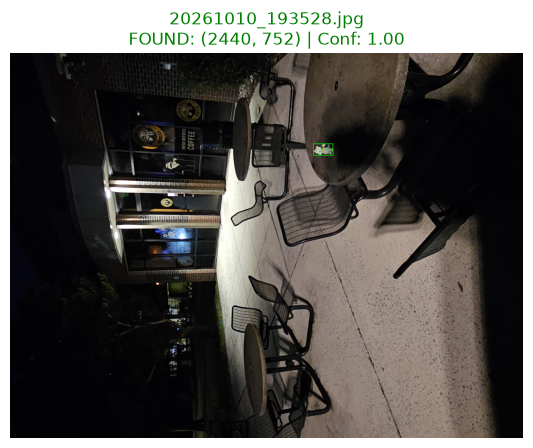

[6/73] Scanning: 20261010_193548(0).jpg    ->  FOUND (1.00)


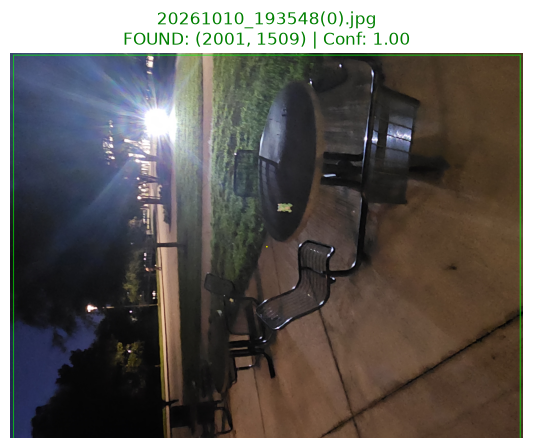

[7/73] Scanning: 20261010_193548.jpg       ->  FOUND (1.00)


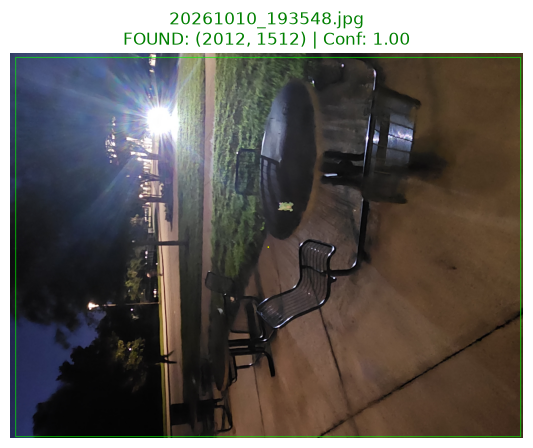

[8/73] Scanning: 20261010_193611.jpg       ->  FOUND (1.00)


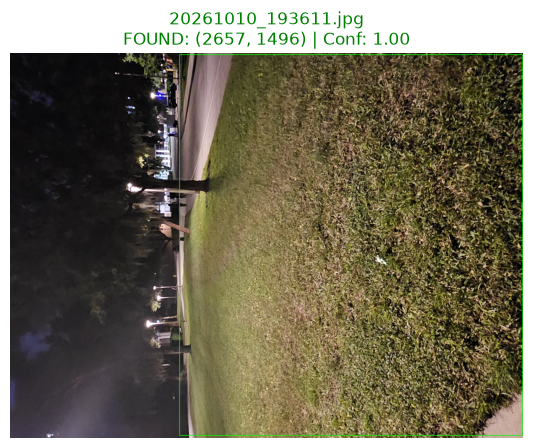

[9/73] Scanning: 20261010_193638.jpg       ->  FOUND (1.00)


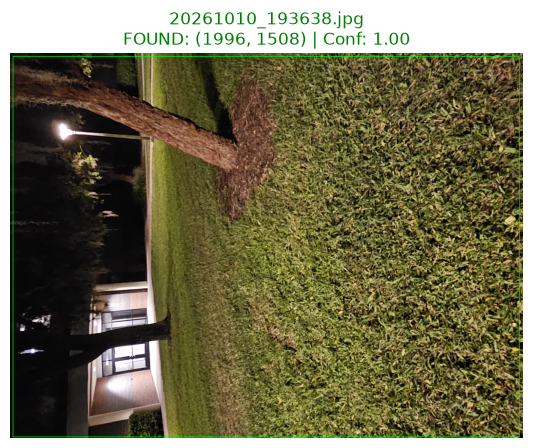

[10/73] Scanning: 20261010_193705.jpg       ->  FOUND (1.00)


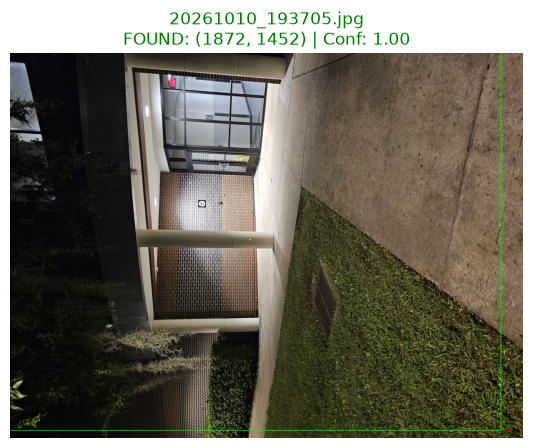

[11/73] Scanning: 20261010_193725.jpg       ->  FOUND (1.00)


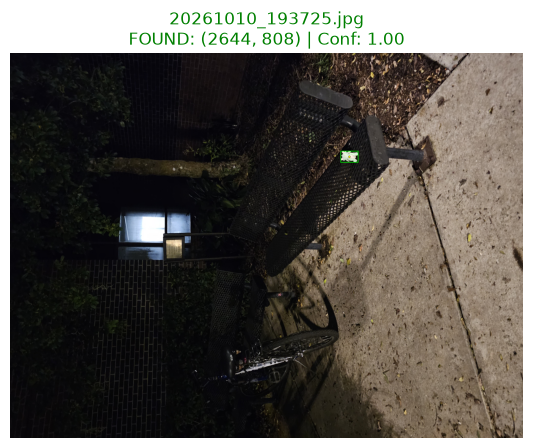

[12/73] Scanning: 20261010_193810.jpg       ->  FOUND (1.00)


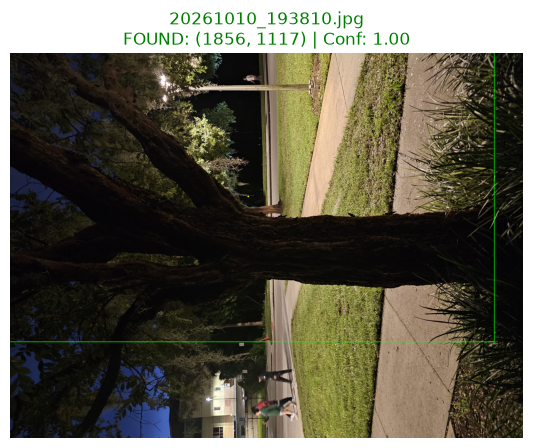

[13/73] Scanning: 20261010_193838.jpg       ->  FOUND (1.00)


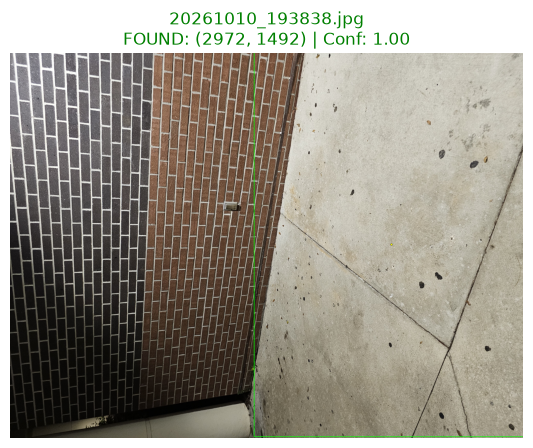

[14/73] Scanning: 20261010_193852.jpg       ->  FOUND (1.00)


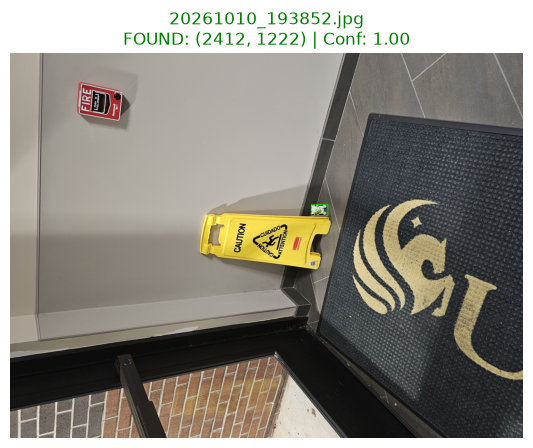

[15/73] Scanning: 20261010_193916.jpg       ->  FOUND (1.00)


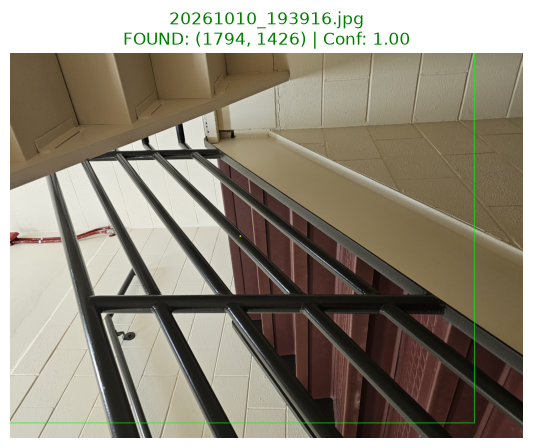

[16/73] Scanning: 20261010_194001.jpg       ->  FOUND (1.00)


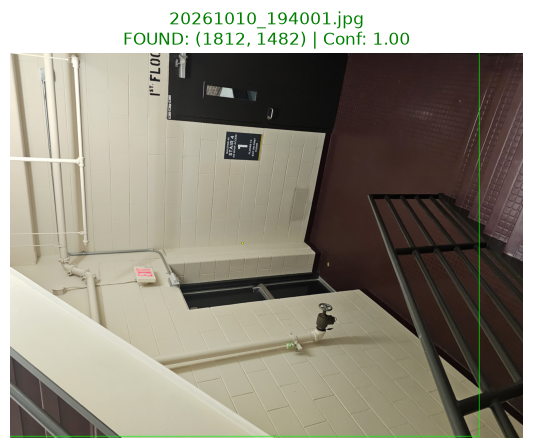

[17/73] Scanning: 20261010_194010.jpg       ->  FOUND (1.00)


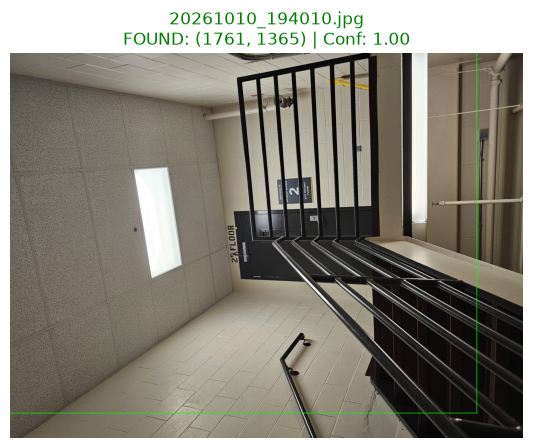

[18/73] Scanning: 20261010_194125.jpg       ->  FOUND (1.00)


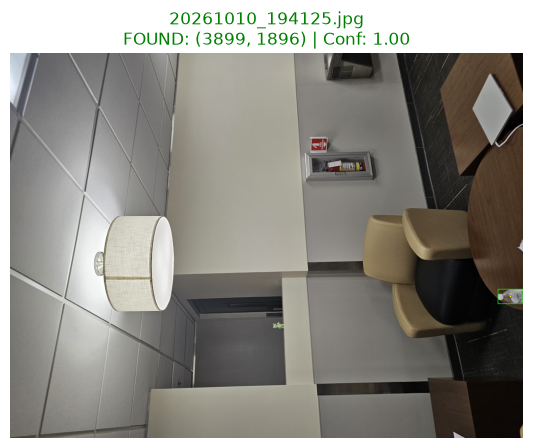

[19/73] Scanning: 20261010_194207.jpg       ->  FOUND (1.00)


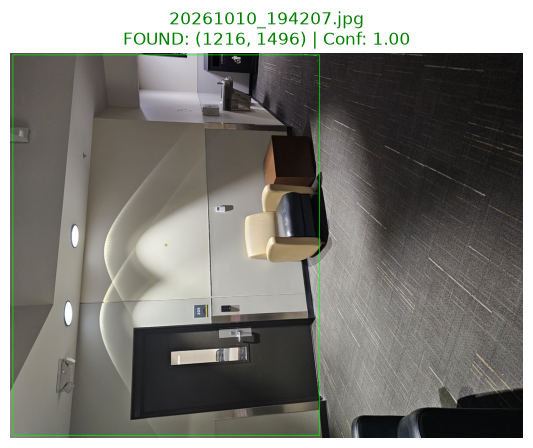

[20/73] Scanning: 20261010_194215.jpg       ->  FOUND (1.00)


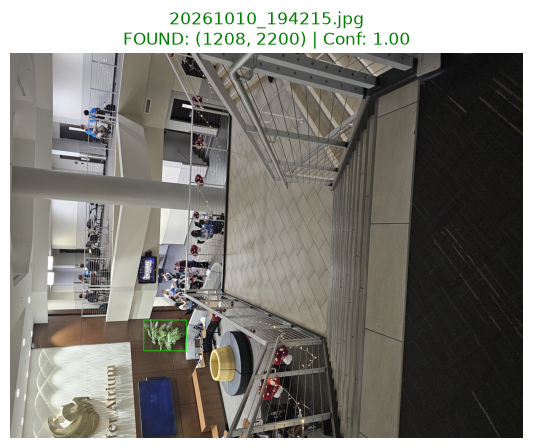

[21/73] Scanning: 20261010_194232.jpg       

In [ ]:
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import torch

# 1. Define base reference images here
BASE_IMAGE_FILENAMES = [
    "lenny1.jpg",
    "lenny2.jpg",
    "lenny3.jpg",
    "lenny4.jpg",
    "lenny5.jpg",
    "lenny6.jpg",
    "lenny7.jpg",
    "lenny8.jpg",
    "lenny9.jpg",
]

def run_full_test(
    image_dir: str = "images",
    output_dir: str = "outputs",
    base_filenames: list = None,
    threshold: float = 0.7,
    save_to_disk: bool = True
):
    if base_filenames is None:
        base_filenames = BASE_IMAGE_FILENAMES

    img_dir = Path(image_dir)
    out_dir = Path(output_dir)
    if save_to_disk:
        out_dir.mkdir(exist_ok=True)

    # 1. Gather all test files (excluding reference files)
    all_files = sorted([
        p for p in img_dir.iterdir() 
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
    ])
    base_lower = [b.lower() for b in base_filenames]
    test_files = [p for p in all_files if p.name.lower() not in base_lower]

    total_images = len(test_files)
    if total_images == 0:
        print(f"No test images found in '{image_dir}' outside of the base reference files!")
        return

    print(f"🚀 Starting Full Test on {total_images} photos across {len(REFERENCE_CROPS)} angles...\n", flush=True)

    # Tracking metrics
    detected_count = 0
    not_detected_count = 0
    scores_list = []

    for idx, img_path in enumerate(test_files, start=1):
        print(f"[{idx}/{total_images}] Scanning: {img_path.name:<25}", end=" ", flush=True)

        with Image.open(img_path) as raw_img:
            search_image = raw_img.convert("RGB")

        width, height = search_image.size
        target_sizes = torch.tensor([[height, width]]).to(device)

        best_box = None
        best_score = -float("inf")

        # 2. Check all reference angles
        for ref_crop in REFERENCE_CROPS:
            inputs = processor(
                images=search_image,
                query_images=ref_crop,
                return_tensors="pt"
            ).to(device)

            with torch.no_grad():
                outputs = model.image_guided_detection(**inputs)

            results = processor.post_process_image_guided_detection(
                outputs=outputs,
                threshold=threshold,
                target_sizes=target_sizes
            )[0]

            boxes = results["boxes"]
            scores = results["scores"]

            if len(boxes) > 0:
                top_idx = torch.argmax(scores).item()
                top_score = scores[top_idx].item()
                if top_score > best_score:
                    best_score = top_score
                    best_box = boxes[top_idx].tolist()

        # 3. Annotate Image
        display_img = search_image.copy()
        draw = ImageDraw.Draw(display_img)

        plt.figure(figsize=(7, 5))

        if best_box is not None:
            detected_count += 1
            scores_list.append(best_score)
            
            xmin, ymin, xmax, ymax = [round(v) for v in best_box]
            cx, cy = round((xmin + xmax) / 2), round((ymin + ymax) / 2)

            # Draw green bounding box & yellow center dot
            draw.rectangle([xmin, ymin, xmax, ymax], outline="#00FF00", width=5)
            draw.ellipse((cx - 8, cy - 8, cx + 8, cy + 8), fill="yellow", outline="black", width=2)

            plt.title(f"{img_path.name}\nFOUND: ({cx}, {cy}) | Conf: {best_score:.2f}", color="green")
            print(f"->  FOUND ({best_score:.2f})", flush=True)
        else:
            not_detected_count += 1
            plt.title(f"{img_path.name}\nNOT DETECTED", color="red")
            print("-> ❌ NOT DETECTED", flush=True)

        # 4. Save to disk so you have all annotated photos ready for your demo
        if save_to_disk:
            display_img.save(out_dir / f"result_{img_path.name}")

        plt.imshow(display_img)
        plt.axis("off")
        plt.show()
        plt.close()  # Free memory after rendering

    # --- FINAL METRICS SUMMARY ---
    avg_score = (sum(scores_list) / len(scores_list)) if scores_list else 0.0
    print("\n" + "=" * 45)
    print("📊 FULL TEST BENCHMARK SUMMARY")
    print("=" * 45)
    print(f"Total Tested Photos  : {total_images}")
    print(f"Lenny Found          : {detected_count} ({detected_count/total_images*100:.1f}%)")
    print(f"Not Detected / Empty : {not_detected_count} ({not_detected_count/total_images*100:.1f}%)")
    print(f"Avg Detection Conf   : {avg_score:.2f}")
    if save_to_disk:
        print(f"All annotated images saved to: '{output_dir}/'")
    print("=" * 45)

# --- RUN FULL TEST ---
run_full_test(threshold=0.45)